In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations


In [3]:
# STEP 1 (load) — combine all 4 hospital Excel files, clean known issues
files = {
    "A": "DRIAMS_A/DRIAMS_A_SHORT_LIST.xlsx",
    "B": "DRIAMS_B/DRIAMS_B_SHORT_LIST.xlsx",
    "C": "DRIAMS_C/DRIAMS_C_SHORT_LIST.xlsx",
    "D": "DRIAMS_D/DRIAMS_D_SHORT_LIST.xlsx",
}

dfs = []
for hospital, path in files.items():
    d = pd.read_excel(path)
    d["hospital"] = hospital #creates new column called "hospital" => labels [A,B,C,D]
    dfs.append(d)

df = pd.concat(dfs, ignore_index=True)
df["Cotrimoxazole"] = df["Cotrimoxazole"].combine_first(df["Cotrimoxazol"])
df = df.drop(columns=["Cotrimoxazol", "Unnamed: 0", "Unnamed: 0.1", "combined_code"], errors="ignore")
print(df.shape)

(21532, 116)


### Data Loading and Integration

The four DRIAMS datasets/hospitals (A, B, C, and D) were combined into a single dataframe. A new `hospital` column was added to preserve the source of each observation.

After combining and cleaning the datasets:

- **Observations:** 21,532
- **Columns:** 116

The columns `Cotrimoxazole` and `Cotrimoxazol` were also merged because they represent the same antibiotic under different spellings.

In [4]:
# STEP 2 — profile ALL antibiotic columns (not just a guessed top-N)
exclude = ["code", "species", "laboratory_species", "genus", "sample_type",
           "year", "hospital", "ESBL", "MRSA", "Quinolones", "Aminoglycosides"] #exculde the non-antibiotic columns
antibiotic_cols = [c for c in df.columns if c not in exclude]

profile = pd.DataFrame({
    "Total_isolates": len(df),
    "R_count": df[antibiotic_cols].apply(lambda c: (c == "R").sum()),
    "S_count": df[antibiotic_cols].apply(lambda c: (c == "S").sum()),
    "I_count": df[antibiotic_cols].apply(lambda c: (c == "I").sum()),
})

profile["Missing_count"] = profile["Total_isolates"] - (profile["R_count"] + profile["S_count"] + profile["I_count"])
profile["Percent_tested"] = ((profile["R_count"] + profile["S_count"] + profile["I_count"]) / profile["Total_isolates"] * 100).round(1)
# I is excluded from the denominator in calculating the R% -> Binary Analysis (R/S)
profile["R_percent"] = (profile["R_count"] / (profile["R_count"] + profile["S_count"]).replace(0, np.nan) * 100).round(1)
profile.sort_values("Percent_tested", ascending=False)

,Total_isolates,R_count,S_count,I_count,Missing_count,Percent_tested,R_percent
Ciprofloxacin,21532,2688,12056,212,6576,69.5,18.2
Amoxicillin-Clavulanic acid,21532,2574,10070,15,8873,58.8,20.4
Cefepime,21532,1304,9813,590,9825,54.4,11.7
Ceftriaxone,21532,2188,9532,4,9808,54.4,18.7
Cotrimoxazole,21532,2704,8704,2,10122,53.0,23.7
...,...,...,...,...,...,...,...
Pristinamycin,21532,0,0,0,21532,0.0,NaN
Quinupristin-Dalfopristin,21532,0,0,0,21532,0.0,NaN
Sparfloxacin,21532,0,0,0,21532,0.0,NaN
Telithromycin,21532,0,0,0,21532,0.0,NaN


In [5]:
# STEP 3 — Build antibiotic selection table
selection_df = pd.DataFrame({
    "Antibiotic": antibiotic_cols,
    "R": [profile.loc[a, "R_count"] for a in antibiotic_cols],
    "S": [profile.loc[a, "S_count"] for a in antibiotic_cols],
    "I": [profile.loc[a, "I_count"] for a in antibiotic_cols]
})

# Total available AST results: R + S + I
selection_df["Tested"] = (
    selection_df["R"] +
    selection_df["S"] +
    selection_df["I"]
)

selection_df["Coverage"] = (
    selection_df["Tested"] / len(df)
)

# Usable observations for our binary R/S analysis
selection_df["RS_Usable"] = (
    selection_df["R"] +
    selection_df["S"]
)

selection_df["RS_Usable_Coverage"] = (
    selection_df["RS_Usable"] / len(df)
)

selection_df = selection_df.sort_values(
    "RS_Usable_Coverage",
    ascending=False
).reset_index(drop=True)

display(selection_df.head(30))

,Antibiotic,R,S,I,Tested,Coverage,RS_Usable,RS_Usable_Coverage
0,Ciprofloxacin,2688,12056,212,14956,0.694594,14744,0.684748
1,Amoxicillin-Clavulanic acid,2574,10070,15,12659,0.587916,12644,0.587219
2,Ceftriaxone,2188,9532,4,11724,0.544492,11720,0.544306
3,Cotrimoxazole,2704,8704,2,11410,0.529909,11408,0.529816
4,Imipenem,719,10624,0,11343,0.526797,11343,0.526797
5,Piperacillin-Tazobactam,1198,9992,55,11245,0.522246,11190,0.519692
6,Cefepime,1304,9813,590,11707,0.543702,11117,0.516301
7,Gentamicin,429,9565,3,9997,0.464286,9994,0.464146
8,Meropenem,715,8789,0,9504,0.441390,9504,0.441390
9,Ampicillin-Amoxicillin,5527,2895,0,8422,0.391139,8422,0.391139


In [6]:
# STEP 4 — Select antibiotics with sufficient usable R/S data
MIN_COVERAGE = 0.20
MIN_RESISTANT = 30

eligible = selection_df[
    (selection_df["RS_Usable_Coverage"] >= MIN_COVERAGE) &
    (selection_df["R"] >= MIN_RESISTANT)
].copy()

eligible = eligible.sort_values(
    by=["RS_Usable_Coverage", "R"],
    ascending=[False, False]
).reset_index(drop=True)

selected = eligible["Antibiotic"].tolist()

print("Number of eligible antibiotics:", len(selected))
display(eligible)

Number of eligible antibiotics: 25


,Antibiotic,R,S,I,Tested,Coverage,RS_Usable,RS_Usable_Coverage
0,Ciprofloxacin,2688,12056,212,14956,0.694594,14744,0.684748
1,Amoxicillin-Clavulanic acid,2574,10070,15,12659,0.587916,12644,0.587219
2,Ceftriaxone,2188,9532,4,11724,0.544492,11720,0.544306
3,Cotrimoxazole,2704,8704,2,11410,0.529909,11408,0.529816
4,Imipenem,719,10624,0,11343,0.526797,11343,0.526797
5,Piperacillin-Tazobactam,1198,9992,55,11245,0.522246,11190,0.519692
6,Cefepime,1304,9813,590,11707,0.543702,11117,0.516301
7,Gentamicin,429,9565,3,9997,0.464286,9994,0.464146
8,Meropenem,715,8789,0,9504,0.441390,9504,0.441390
9,Ampicillin-Amoxicillin,5527,2895,0,8422,0.391139,8422,0.391139


In [7]:
# STEP 5 — Check pairwise co-testing among selected antibiotics
cotest_results = []

for a, b in combinations(selected, 2):

    valid = df[[a, b]].copy()

    valid[a] = valid[a].astype(str).str.strip().str.upper()
    valid[b] = valid[b].astype(str).str.strip().str.upper()

    valid = valid[
        valid[a].isin(["R", "S"]) &
        valid[b].isin(["R", "S"])
    ]

    n_cotested = len(valid)

    cotest_results.append({
        "Antibiotic_A": a,
        "Antibiotic_B": b,
        "N_Cotested": n_cotested,
        "Pct_of_Dataset": n_cotested / len(df) * 100
    })

cotest_df = pd.DataFrame(cotest_results)

print("Number of selected antibiotics:", len(selected))
print("Number of possible pairs:", len(cotest_df))

display(
    cotest_df.sort_values("N_Cotested").reset_index(drop=True)
)

Number of selected antibiotics: 25
Number of possible pairs: 300


,Antibiotic_A,Antibiotic_B,N_Cotested,Pct_of_Dataset
0,Erythromycin,Tobramycin,0,0.000000
1,Amikacin,Fusidic acid,0,0.000000
2,Amikacin,Daptomycin,0,0.000000
3,Amikacin,Erythromycin,0,0.000000
4,Amikacin,Oxacillin,0,0.000000
...,...,...,...,...
295,Amoxicillin-Clavulanic acid,Imipenem,11149,51.778748
296,Ceftriaxone,Imipenem,11298,52.470741
297,Ciprofloxacin,Ceftriaxone,11333,52.633290
298,Amoxicillin-Clavulanic acid,Ceftriaxone,11529,53.543563


In [8]:
# STEP 6 — Examine pairwise co-testing distribution
print("Summary of N_Cotested:")
display(cotest_df["N_Cotested"].describe())

thresholds = [10, 30, 50, 100, 200, 500, 1000]

print("\nPairs below possible thresholds:")
for threshold in thresholds:
    n_below = (cotest_df["N_Cotested"] < threshold).sum()
    pct_below = n_below / len(cotest_df) * 100

    print(
        f"< {threshold}: {n_below} pairs "
        f"({pct_below:.1f}%)"
    )

Summary of N_Cotested:


count      300.000000
mean      4344.576667
std       2896.695292
min          0.000000
25%       3542.500000
50%       4221.000000
75%       5619.250000
max      12269.000000
Name: N_Cotested, dtype: float64


Pairs below possible thresholds:
< 10: 38 pairs (12.7%)
< 30: 38 pairs (12.7%)
< 50: 38 pairs (12.7%)
< 100: 38 pairs (12.7%)
< 200: 38 pairs (12.7%)
< 500: 51 pairs (17.0%)
< 1000: 55 pairs (18.3%)


In [9]:
# STEP 7 — Calculate pairwise R/S resistance combinations
pair_results = []

for a, b in combinations(selected, 2):

    # Keep only the two antibiotics being compared
    valid = df[[a, b]].copy()

    # Standardize AST labels
    valid[a] = valid[a].astype(str).str.strip().str.upper()
    valid[b] = valid[b].astype(str).str.strip().str.upper()

    # Keep only isolates with definitive R/S results for BOTH antibiotics
    valid = valid[
        valid[a].isin(["R", "S"]) &
        valid[b].isin(["R", "S"])
    ]

    # Number of isolates co-tested for this pair
    n_cotested = len(valid)

    # Four possible R/S combinations
    rr = ((valid[a] == "R") & (valid[b] == "R")).sum()
    rs = ((valid[a] == "R") & (valid[b] == "S")).sum()
    sr = ((valid[a] == "S") & (valid[b] == "R")).sum()
    ss = ((valid[a] == "S") & (valid[b] == "S")).sum()

    pair_results.append({
        "Antibiotic_A": a,
        "Antibiotic_B": b,
        "N_Cotested": n_cotested,
        "RR": rr,
        "RS": rs,
        "SR": sr,
        "SS": ss
    })

pair_results_df = pd.DataFrame(pair_results)

print("Number of calculated pairs:", len(pair_results_df))

display(pair_results_df.head(10))

Number of calculated pairs: 300


,Antibiotic_A,Antibiotic_B,N_Cotested,RR,RS,SR,SS
0,Ciprofloxacin,Amoxicillin-Clavulanic acid,12269,1144,1275,1341,8509
1,Ciprofloxacin,Ceftriaxone,11333,1302,1136,772,8123
2,Ciprofloxacin,Cotrimoxazole,11055,1131,1221,1453,7250
3,Ciprofloxacin,Imipenem,10961,294,2046,412,8209
4,Ciprofloxacin,Piperacillin-Tazobactam,10816,556,1722,601,7937
5,Ciprofloxacin,Cefepime,10785,729,1220,540,8296
6,Ciprofloxacin,Gentamicin,9766,228,1026,170,8342
7,Ciprofloxacin,Meropenem,9172,293,1711,409,6759
8,Ciprofloxacin,Ampicillin-Amoxicillin,8127,1637,158,3636,2696
9,Ciprofloxacin,Ceftazidime,7360,583,1061,240,5476


In [10]:
print(
    "All counts sum correctly:",
    (
        pair_results_df["RR"]
        + pair_results_df["RS"]
        + pair_results_df["SR"]
        + pair_results_df["SS"]
        == pair_results_df["N_Cotested"]
    ).all()
)

All counts sum correctly: True


In [11]:
# STEP 8 — Calculate pairwise resistance-overlap measures

# Number resistant to at least one antibiotic in the pair
pair_results_df["N_Resistant_Union"] = (
    pair_results_df["RR"]
    + pair_results_df["RS"]
    + pair_results_df["SR"]
)

# Proportion of all co-tested isolates resistant to both
pair_results_df["Joint_R_Prevalence"] = np.where(
    pair_results_df["N_Cotested"] > 0,
    pair_results_df["RR"] / pair_results_df["N_Cotested"],
    np.nan
)

# Normalized overlap among isolates resistant to at least one antibiotic
pair_results_df["Normalized_CR"] = np.where(
    pair_results_df["N_Resistant_Union"] > 0,
    pair_results_df["RR"] / pair_results_df["N_Resistant_Union"],
    np.nan
)

display(
    pair_results_df[
        [
            "Antibiotic_A",
            "Antibiotic_B",
            "N_Cotested",
            "RR",
            "RS",
            "SR",
            "SS",
            "N_Resistant_Union",
            "Joint_R_Prevalence",
            "Normalized_CR"
        ]
    ].head(10)
)

,Antibiotic_A,Antibiotic_B,N_Cotested,RR,RS,SR,SS,N_Resistant_Union,Joint_R_Prevalence,Normalized_CR
0,Ciprofloxacin,Amoxicillin-Clavulanic acid,12269,1144,1275,1341,8509,3760,0.093243,0.304255
1,Ciprofloxacin,Ceftriaxone,11333,1302,1136,772,8123,3210,0.114886,0.405607
2,Ciprofloxacin,Cotrimoxazole,11055,1131,1221,1453,7250,3805,0.102307,0.297240
3,Ciprofloxacin,Imipenem,10961,294,2046,412,8209,2752,0.026822,0.106831
4,Ciprofloxacin,Piperacillin-Tazobactam,10816,556,1722,601,7937,2879,0.051405,0.193123
5,Ciprofloxacin,Cefepime,10785,729,1220,540,8296,2489,0.067594,0.292889
6,Ciprofloxacin,Gentamicin,9766,228,1026,170,8342,1424,0.023346,0.160112
7,Ciprofloxacin,Meropenem,9172,293,1711,409,6759,2413,0.031945,0.121426
8,Ciprofloxacin,Ampicillin-Amoxicillin,8127,1637,158,3636,2696,5431,0.201427,0.301418
9,Ciprofloxacin,Ceftazidime,7360,583,1061,240,5476,1884,0.079212,0.309448


In [12]:
# STEP 9 — Examine resistance-positive sample size
MIN_COTESTED = 200

cotested_pairs = pair_results_df[
    pair_results_df["N_Cotested"] >= MIN_COTESTED
].copy()

print("Pairs with N_Cotested >= 200:", len(cotested_pairs))

print("\nSummary of N_Resistant_Union:")
display(cotested_pairs["N_Resistant_Union"].describe())

thresholds = [1, 5, 10, 20, 30, 50, 100, 200]

print("\nPairs below possible resistance-positive thresholds:")
for threshold in thresholds:

    n_below = (
        cotested_pairs["N_Resistant_Union"] < threshold
    ).sum()

    pct_below = (
        n_below / len(cotested_pairs) * 100
    )

    print(
        f"< {threshold}: {n_below} pairs "
        f"({pct_below:.1f}%)"
    )

Pairs with N_Cotested >= 200: 262

Summary of N_Resistant_Union:


count     262.00000
mean     1364.01145
std      1225.42037
min        10.00000
25%       666.75000
50%       960.50000
75%      1879.00000
max      5567.00000
Name: N_Resistant_Union, dtype: float64


Pairs below possible resistance-positive thresholds:
< 1: 0 pairs (0.0%)
< 5: 0 pairs (0.0%)
< 10: 0 pairs (0.0%)
< 20: 5 pairs (1.9%)
< 30: 13 pairs (5.0%)
< 50: 19 pairs (7.3%)
< 100: 25 pairs (9.5%)
< 200: 32 pairs (12.2%)


In [13]:
print("Resistance-positive denominator summary:")

print(
    pair_results_df[
        pair_results_df["N_Cotested"] >= 200
    ]["N_Resistant_Union"].describe()
)

thresholds = [1, 5, 10, 20, 30, 50, 100, 200]

print("\nPairs below each resistant-union threshold:")

eligible_pairs = pair_results_df[
    pair_results_df["N_Cotested"] >= 200
]

for threshold in thresholds:

    n = (
        eligible_pairs["N_Resistant_Union"] < threshold
    ).sum()

    pct = n / len(eligible_pairs) * 100

    print(
        f"< {threshold:3}: "
        f"{n:3} pairs ({pct:.1f}%)"
    )

Resistance-positive denominator summary:
count     262.00000
mean     1364.01145
std      1225.42037
min        10.00000
25%       666.75000
50%       960.50000
75%      1879.00000
max      5567.00000
Name: N_Resistant_Union, dtype: float64

Pairs below each resistant-union threshold:
<   1:   0 pairs (0.0%)
<   5:   0 pairs (0.0%)
<  10:   0 pairs (0.0%)
<  20:   5 pairs (1.9%)
<  30:  13 pairs (5.0%)
<  50:  19 pairs (7.3%)
< 100:  25 pairs (9.5%)
< 200:  32 pairs (12.2%)


In [14]:
# STEP 10 — Apply pair-level reliability criteria

MIN_COTESTED = 200
MIN_RESISTANT_UNION = 30

pair_results_df["Eligible"] = (
    (pair_results_df["N_Cotested"] >= MIN_COTESTED) &
    (pair_results_df["N_Resistant_Union"] >= MIN_RESISTANT_UNION)
)

# Keep the raw Normalized_CR, but create a filtered version
# for the final heatmap and pattern analysis.
pair_results_df["Filtered_CR"] = np.where(
    pair_results_df["Eligible"],
    pair_results_df["Normalized_CR"],
    np.nan
)

print("Total possible pairs:", len(pair_results_df))
print("Eligible pairs:", pair_results_df["Eligible"].sum())
print("Ineligible pairs:", (~pair_results_df["Eligible"]).sum())

display(
    pair_results_df[
        [
            "Antibiotic_A",
            "Antibiotic_B",
            "N_Cotested",
            "N_Resistant_Union",
            "Normalized_CR",
            "Eligible",
            "Filtered_CR"
        ]
    ].head(10)
)

Total possible pairs: 300
Eligible pairs: 249
Ineligible pairs: 51


,Antibiotic_A,Antibiotic_B,N_Cotested,N_Resistant_Union,Normalized_CR,Eligible,Filtered_CR
0,Ciprofloxacin,Amoxicillin-Clavulanic acid,12269,3760,0.304255,True,0.304255
1,Ciprofloxacin,Ceftriaxone,11333,3210,0.405607,True,0.405607
2,Ciprofloxacin,Cotrimoxazole,11055,3805,0.297240,True,0.297240
3,Ciprofloxacin,Imipenem,10961,2752,0.106831,True,0.106831
4,Ciprofloxacin,Piperacillin-Tazobactam,10816,2879,0.193123,True,0.193123
5,Ciprofloxacin,Cefepime,10785,2489,0.292889,True,0.292889
6,Ciprofloxacin,Gentamicin,9766,1424,0.160112,True,0.160112
7,Ciprofloxacin,Meropenem,9172,2413,0.121426,True,0.121426
8,Ciprofloxacin,Ampicillin-Amoxicillin,8127,5431,0.301418,True,0.301418
9,Ciprofloxacin,Ceftazidime,7360,1884,0.309448,True,0.309448


In [15]:
pair_results_df["Filtered_CR"] = np.where(
    pair_results_df["Eligible"],
    pair_results_df["Normalized_CR"],
    np.nan
)

print("\nFiltered CR values available:",
      pair_results_df["Filtered_CR"].notna().sum())


Filtered CR values available: 249


In [16]:
# STEP 11 — Build the normalized resistance-overlap matrix
cr_matrix = pd.DataFrame(
    np.nan,
    index=selected,
    columns=selected,
    dtype=float
)

for _, row in pair_results_df.iterrows():

    a = row["Antibiotic_A"]
    b = row["Antibiotic_B"]

    if row["Eligible"]:
        value = row["Normalized_CR"]

        cr_matrix.loc[a, b] = value
        cr_matrix.loc[b, a] = value

# Leave diagonal blank
np.fill_diagonal(cr_matrix.values, np.nan)

display(cr_matrix)

,Ciprofloxacin,Amoxicillin-Clavulanic acid,Ceftriaxone,Cotrimoxazole,Imipenem,Piperacillin-Tazobactam,Cefepime,Gentamicin,Meropenem,Ampicillin-Amoxicillin,...,Penicillin,Erythromycin,Fosfomycin,Levofloxacin,Oxacillin,Tobramycin,Cefuroxime,Fusidic acid,Clindamycin,Daptomycin
Ciprofloxacin,NaN,0.304255,0.405607,0.297240,0.106831,0.193123,0.292889,0.160112,0.121426,0.301418,...,0.122028,0.175799,0.035620,1.000000,0.304688,0.307692,0.351151,0.078457,0.140831,0.016978
Amoxicillin-Clavulanic acid,0.304255,NaN,0.454374,0.254532,0.292057,0.509418,0.465560,0.143583,0.344247,0.349100,...,0.238367,0.247569,0.032702,0.306573,0.989770,0.294515,0.802026,0.118280,0.202936,0.011936
Ceftriaxone,0.405607,0.454374,NaN,0.247103,0.327665,0.410235,0.812419,0.153188,0.365128,0.326182,...,0.272588,0.252544,0.032020,0.482911,0.988889,0.329830,0.948583,0.120238,0.208540,0.012278
Cotrimoxazole,0.297240,0.254532,0.247103,NaN,0.020231,0.116170,0.132815,0.172819,0.023938,0.277708,...,0.049360,0.048750,0.027714,0.332707,0.078251,0.230857,0.163772,0.064356,0.033708,0.000000
Imipenem,0.106831,0.292057,0.327665,0.020231,NaN,0.603201,0.557467,0.084103,0.997211,0.129985,...,0.272588,0.252544,0.023256,0.002244,0.988889,0.000000,0.759062,0.120238,0.208540,0.012278
Piperacillin-Tazobactam,0.193123,0.509418,0.410235,0.116170,0.603201,NaN,0.582557,0.111511,0.651184,0.189385,...,0.272379,0.252544,0.035176,0.118962,0.988889,0.149394,0.835979,0.120238,0.208540,0.012278
Cefepime,0.292889,0.465560,0.812419,0.132815,0.557467,0.582557,NaN,0.149333,0.622378,0.212170,...,0.272588,0.247569,0.048387,0.263056,0.989204,0.285217,0.932973,0.122286,0.207780,0.011936
Gentamicin,0.160112,0.143583,0.153188,0.172819,0.084103,0.111511,0.149333,NaN,0.098660,0.036273,...,0.028616,0.052968,0.039216,NaN,0.111247,NaN,0.141885,0.074380,0.070365,0.012121
Meropenem,0.121426,0.344247,0.365128,0.023938,0.997211,0.651184,0.622378,0.098660,NaN,0.129529,...,0.272588,0.252544,NaN,0.002235,0.988889,0.000000,0.928292,0.120238,0.208540,0.012278
Ampicillin-Amoxicillin,0.301418,0.349100,0.326182,0.277708,0.129985,0.189385,0.212170,0.036273,0.129529,NaN,...,0.999617,0.191811,NaN,0.428870,0.275440,0.209270,0.272379,0.071915,0.150038,0.011098


In [17]:
print("Matrix shape:", cr_matrix.shape)

print("Matrix symmetric:", cr_matrix.equals(cr_matrix.T))

print(
    "Non-missing unique pairs:",
    cr_matrix.notna().sum().sum() // 2
)

Matrix shape: (25, 25)
Matrix symmetric: True
Non-missing unique pairs: 249


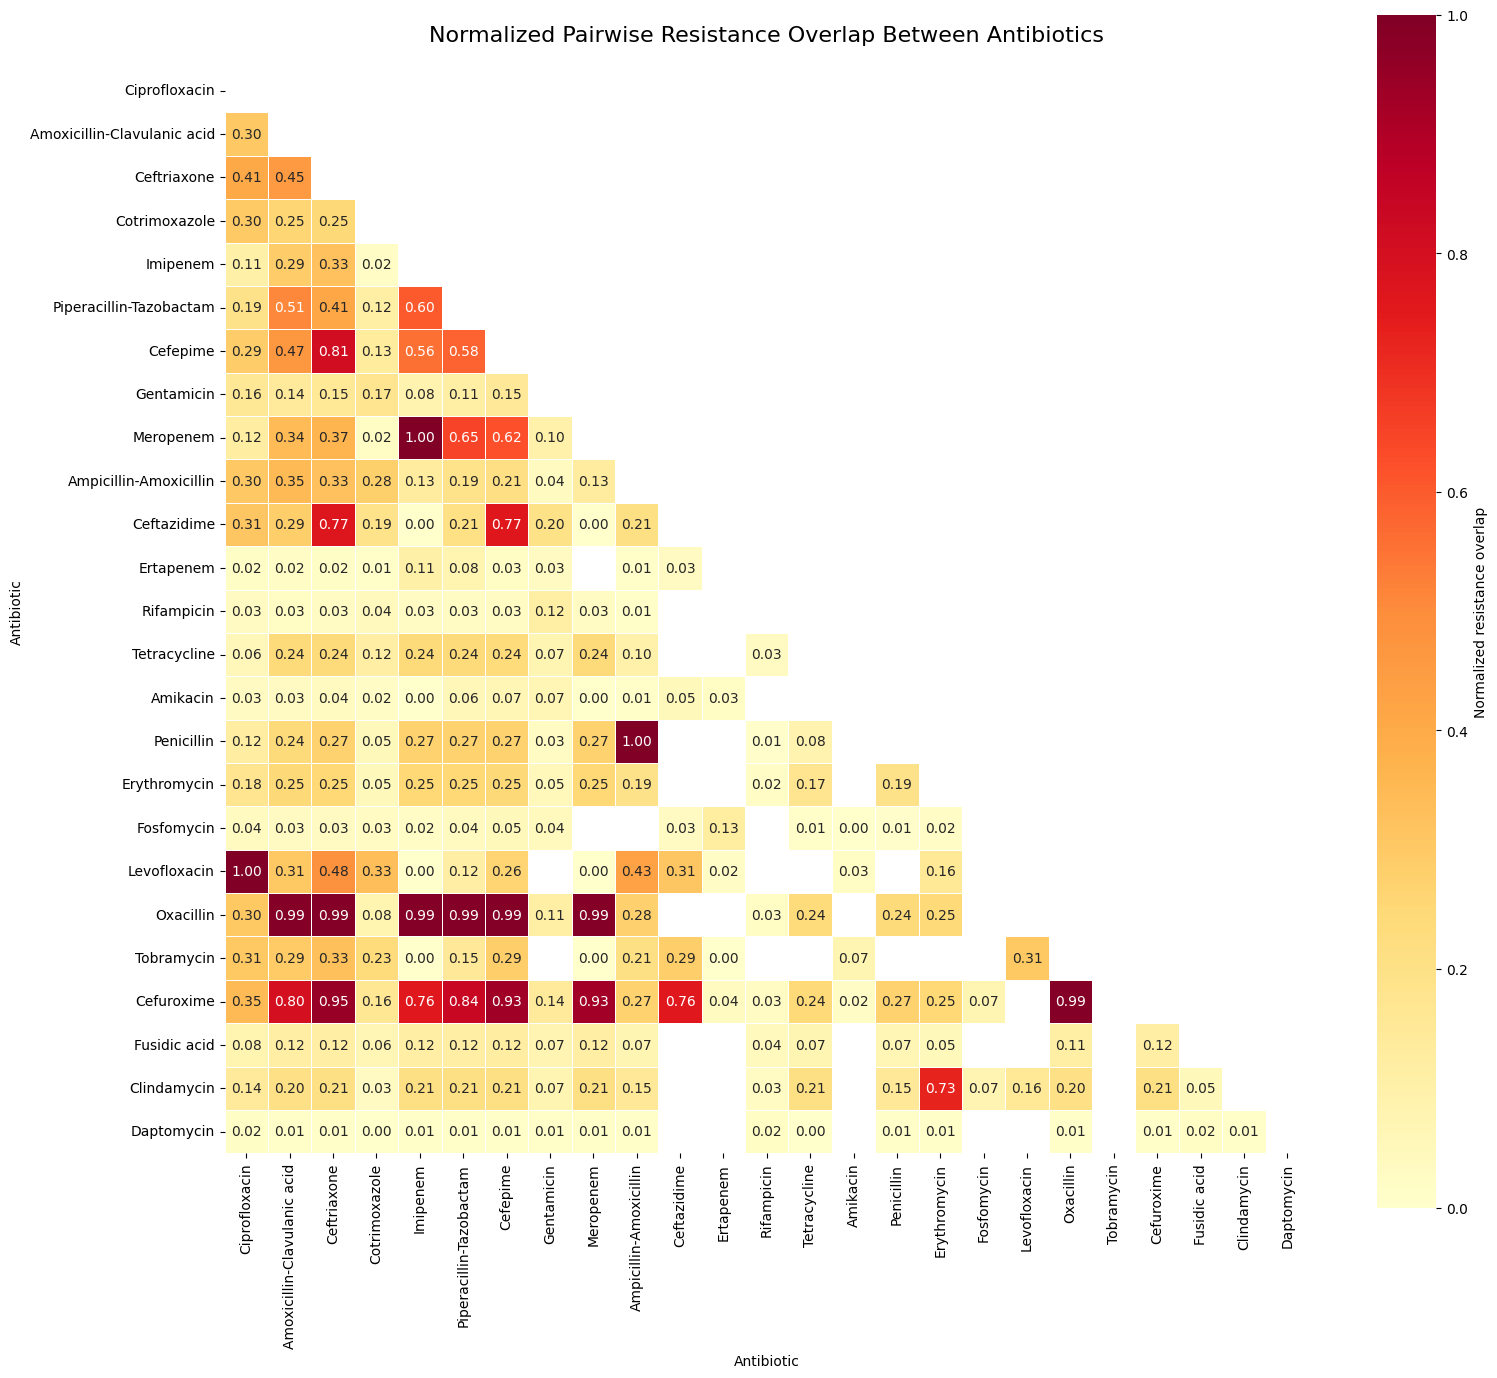

In [18]:
# STEP 12 — Plot triangular normalized resistance-overlap heatmap

# Mask the upper triangle, including the diagonal
triangle_mask = np.triu(
    np.ones(cr_matrix.shape, dtype=bool),
    k=0
)

# Also mask unavailable/ineligible comparisons
final_mask = triangle_mask | cr_matrix.isna().values

plt.figure(figsize=(16, 14))

sns.heatmap(
    cr_matrix,
    mask=final_mask,
    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={
        "label": "Normalized resistance overlap"
    }
)

plt.title(
    "Normalized Pairwise Resistance Overlap Between Antibiotics",
    fontsize=16,
    pad=20
)

plt.xlabel("Antibiotic")
plt.ylabel("Antibiotic")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [19]:
# STEP 13 — Rank eligible antibiotic pairs by normalized resistance overlap
ranked_pairs = (
    pair_results_df[
        pair_results_df["Eligible"]
    ]
    .sort_values(
        "Normalized_CR",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    ranked_pairs[
        [
            "Antibiotic_A",
            "Antibiotic_B",
            "N_Cotested",
            "RR",
            "RS",
            "SR",
            "N_Resistant_Union",
            "Normalized_CR"
        ]
    ].head(25)
)

,Antibiotic_A,Antibiotic_B,N_Cotested,RR,RS,SR,N_Resistant_Union,Normalized_CR
0,Ciprofloxacin,Levofloxacin,5098,1360,0,0,1360,1.000000
1,Ampicillin-Amoxicillin,Penicillin,3554,2611,0,1,2612,0.999617
2,Imipenem,Meropenem,9479,715,2,0,717,0.997211
3,Amoxicillin-Clavulanic acid,Oxacillin,4723,774,0,8,782,0.989770
4,Cefepime,Oxacillin,3985,733,0,8,741,0.989204
5,Piperacillin-Tazobactam,Oxacillin,3641,712,0,8,720,0.988889
6,Meropenem,Oxacillin,3642,712,0,8,720,0.988889
7,Ceftriaxone,Oxacillin,3639,712,0,8,720,0.988889
8,Imipenem,Oxacillin,3640,712,0,8,720,0.988889
9,Oxacillin,Cefuroxime,3639,712,8,0,720,0.988889
